# 任務 6：探索變數關係
目標：畫散布圖、計算相關係數並分辨關聯與因果。

**學生版**｜與教師版任務及小節編號一一對應

## 開始之前
姓名：＿田紹廷＿＿＿　學號：＿C114118141＿＿＿

本教材可以在 Colab 或 Jupyter 執行，請依序執行儲存格。每份任務的準備儲存格會在記憶體重新建立相同的模擬資料，不會覆寫 CSV。若要分析自己先前產生的 CSV，先上傳檔案，執行準備儲存格後再執行 `df = pd.read_csv("student_learning_data.csv")`；不同資料的驗證數字可能不同。

成績是人為公式生成，資料品質問題在計分後加入。結果只描述模擬資料，不能推論真實學生或證明因果。每個任務請先預測，執行後修改與驗證，最後用自己的話解釋。

### 學生操作方式
1. 先執行下一個完整的資料準備儲存格。每份任務可獨立執行；重啟環境後請由上而下重新執行。
2. 在每個小節的程式中，將 `___` 替換成符合題意的程式碼，並把 `# 學生註解` 改成自己的繁體中文解說（至少說明指定程式的輸入／處理／輸出）。`___` 是刻意留下的空格，完成前執行會報錯。
3. 先記錄預測，執行後完成驗證與解釋；再完成延伸練習。遇到困難可以使用小節專屬 AI 提示詞，仍須檢查、修改、執行與理解。
4. 在文字儲存格中填寫答案，保留程式、執行結果、圖表和 AI 使用紀錄。依教師指示交付已完成的 `.ipynb`。首次執行任務 1 的存檔程式會覆寫同名 practice_student_data.csv，請先確認或改檔名。


In [1]:
# 載入分析與繪圖套件；np、pd、plt 是慣用縮寫
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 固定種子及呼叫順序，使本課範例能重現
rng = np.random.default_rng(42)
n = 60  # 模擬學生人數
departments = ["資訊管理", "企業管理", "金融管理"]
# 字典每個鍵是欄位名稱，每個值提供 60 位學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)  # 把字典轉成資料表
noise = rng.normal(0, 5, n)  # 模擬其他未觀察的差異
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)  # 限制 0 到 100 分
df.loc[[5, 17], "sleep_hours"] = np.nan  # 成績算完後才加入缺失
df.loc[8, "screen_time_hours"] = 15.0  # 成績算完後才加入異常值
print("資料已準備：", df.shape)

資料已準備： (60, 7)


## 6.1 有效配對
相關分析需要每位學生的兩個欄位都有值；缺失一方的資料無法形成有效配對。
**預測：** 睡眠與成績有幾組有效配對？

### 學生練習 6.1：完成程式與註解

- **程式填空：** 補上只排除 sleep_hours 或 quiz_score 缺失資料列的運算。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：**（請填寫）

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 6.1。我的資料表叫 df，請教我如何補上只排除 sleep_hours 或 quiz_score 缺失資料列的運算。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


In [2]:
# 學生註解 1：請說明填空程式的輸入、處理與輸出
pairs = df.dropna(subset=["sleep_hours", "quiz_score"])
print("有效配對數：", len(pairs))
print("原始列數：", len(df))
# 學生註解 2：請選另一行程式說明其作用


有效配對數： 58
原始列數： 60


### 驗證、解釋與延伸 6.1

**驗證與解釋：** 有效配對數及原始筆數各是多少？減少幾筆？

**我的結果與解釋（引用實際輸出）：**（請填寫）

**延伸練習：** 自行檢查配對表的兩個欄位各有多少缺失。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：**（請填寫）

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：自行檢查配對表的兩個欄位各有多少缺失。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


In [3]:
# 在此撰寫延伸練習與自己的註解


## 6.2 散布圖
每個點代表一位學生，橫軸是讀書時數，縱軸是成績。觀察方向、分散與特殊點。

### 學生練習 6.2：完成程式與註解

- **程式填空：** 補上以 study_hours 為橫軸、quiz_score 為縱軸的散布圖指令。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：**（請填寫）

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 6.2。我的資料表叫 df，請教我如何補上以 study_hours 為橫軸、quiz_score 為縱軸的散布圖指令。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


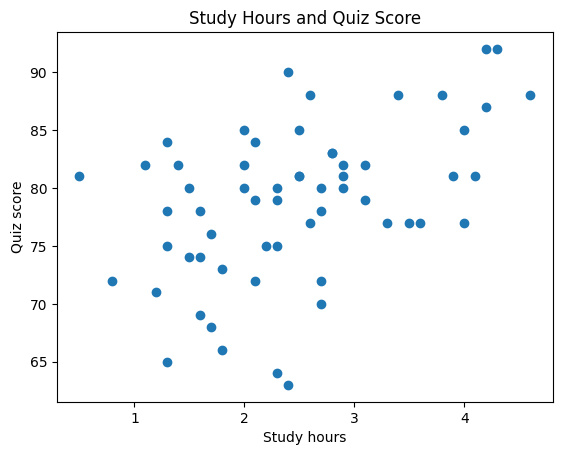

In [4]:
# 學生註解 1：請說明填空程式的輸入、處理與輸出
study_pairs = df.dropna(subset=["study_hours", "quiz_score"])
plt.scatter(study_pairs["study_hours"], study_pairs["quiz_score"])
plt.xlabel("Study hours")
plt.ylabel("Quiz score")
plt.title("Study Hours and Quiz Score")
plt.show()
# 學生註解 2：請選另一行程式說明其作用


### 驗證、解釋與延伸 6.2

**驗證與解釋：** 每個點代表什麼？大致方向與分散情形為何？

**我的結果與解釋（引用實際輸出）：**（請填寫）

**延伸練習：** 改用 sleep_hours 與 quiz_score 畫圖，記錄有效配對數。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：**（請填寫）

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：改用 sleep_hours 與 quiz_score 畫圖，記錄有效配對數。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


In [5]:
# 在此撰寫延伸練習與自己的註解


## 6.3 Pearson 相關係數
相關係數介於 -1 和 1；正負表示線性方向，靠近 0 表示線性關係較弱。不要只靠一個數字判斷，應搭配散布圖與有效筆數。

### 學生練習 6.3：完成程式與註解

- **程式填空：** 補上讀書時數與成績的 Pearson 相關係數計算。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：**（請填寫）

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 6.3。我的資料表叫 df，請教我如何補上讀書時數與成績的 Pearson 相關係數計算。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


In [6]:
# 學生註解 1：請說明填空程式的輸入、處理與輸出
study_corr = study_pairs["study_hours"].corr(study_pairs["quiz_score"])
sleep_corr = pairs["sleep_hours"].corr(pairs["quiz_score"])
print("讀書配對數與相關：", len(study_pairs), study_corr)
print("睡眠配對數與相關：", len(pairs), sleep_corr)
# 學生註解 2：請選另一行程式說明其作用


讀書配對數與相關： 60 0.47124780969140034
睡眠配對數與相關： 58 -0.015255866695473633


### 驗證、解釋與延伸 6.3

**驗證與解釋：** 記錄兩組配對數與係數，正負號代表什麼？為何不能據此斷言因果？

**我的結果與解釋（引用實際輸出）：**（請填寫）

**延伸練習：** 計算 screen_time_hours 與 quiz_score 的相關係數和有效配對數。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：**（請填寫）

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：計算 screen_time_hours 與 quiz_score 的相關係數和有效配對數。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


In [7]:
# 在此撰寫延伸練習與自己的註解


## 任務交付與 AI 使用紀錄

完成本任務的三個小節，儲存含輸出的 Notebook，依教師指定的方式繳交。任務 8 另需完成 8.3 的完整分析報告及其佐證圖表。

- 使用的 AI 提示詞（未使用請填「未使用」）：
- AI 建議中我修改或拒絕的一處及原因：
- 遇到的錯誤或疑問、修正與驗證方式：
- 本任務一項有數據支持的發現及對應儲存格：
- 一項資料或推論限制：

**交付前檢核：** 已填完程式空格與註解；已填寫預測、驗證、解釋與延伸；已由上到下執行並確認圖表和數字與文字一致。
